# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

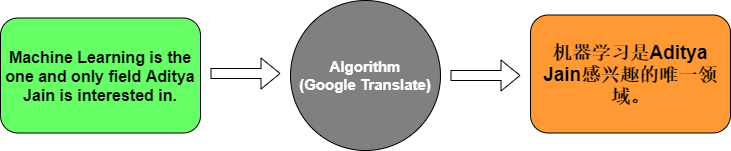

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step - accuracy: 0.0000e+00 - loss: 2.4877 - val_accuracy: 0.0000e+00 - val_loss: 2.4893
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.5714 - loss: 2.4791 - val_accuracy: 0.0000e+00 - val_loss: 2.4916
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.5714 - loss: 2.4708 - val_accuracy: 0.0000e+00 - val_loss: 2.4941
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.5714 - loss: 2.4621 - val_accuracy: 0.0000e+00 - val_loss: 2.4970
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - accuracy: 0.5714 - loss: 2.4526 - val_accuracy: 0.0000e+00 - val_loss: 2.5003
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.5714 - loss: 2.4418 - val_accuracy: 0.0000e+00 - val_loss: 2.5042
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.5714 - loss: 2.4293 - val_accuracy: 0.0000e+00 - val_loss: 2.5088
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.5714 - loss: 2.4147 - val_accu

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step
Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


> **Your answer:**
>
> 1. **Embedding:** takes the word index (just a number like 5) and turns it into a dense vector (64 numbers here). The model learns these vectors while training, so words with similar meaning end up close to each other.
> 2. **Encoder LSTM:** reads the English sentence word by word and squeezes the whole thing into one vector (its last hidden state), basically a summary of what the sentence means.
> 3. **Decoder LSTM:** takes that summary (repeated for each output step by `RepeatVector`) and spits out a sequence, one step per French word, using `return_sequences=True`.
> 4. **Softmax:** at each step we need to pick one word from the whole French vocab, so softmax turns the raw scores into probabilities that add up to 1, then we just take the argmax as the predicted word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [8]:
#!pip install kagglehub
import kagglehub, os
import pandas as pd

# download the dataset from kaggle
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "eng_-french.csv"))
df.columns = ["eng", "frn"]
print(df.shape)
df.head()

Using Colab cache for faster access to the 'language-translation-englishfrench' dataset.
['eng_-french.csv']
(175621, 2)


,eng,frn
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


The full dataset is ~175k pairs which is way too much for this simple model, so I'll keep short sentences only and take a sample.

In [9]:
# keep short sentences only (<= 6 words) and take a sample so training doesn't take forever
df = df.dropna()
df = df[(df["eng"].str.split().str.len() <= 6) & (df["frn"].str.split().str.len() <= 6)]
df = df.sample(20000, random_state=42).reset_index(drop=True)
print(df.shape)
df.head()

(20000, 2)


,eng,frn
0,We got too close.,On s'est trop rapprochés.
1,A student wants to see you.,Un étudiant veut te voir.
2,You're not often wrong.,Vous n'avez pas souvent tort.
3,We're conducting a survey.,Nous faisons un sondage.
4,Was that you at the door?,Était-ce toi à la porte ?


In [10]:
# Tokenize both languages (same as the example above)
# filters without the apostrophe so words like "c'est" stay as one token
flt = Tokenizer().filters.replace("'", "")

tok_eng = Tokenizer(filters=flt)
tok_eng.fit_on_texts(df["eng"])
eng_seq = tok_eng.texts_to_sequences(df["eng"])

tok_frn = Tokenizer(filters=flt)
tok_frn.fit_on_texts(df["frn"])
frn_seq = tok_frn.texts_to_sequences(df["frn"])

eng_vocab = len(tok_eng.word_index) + 1
frn_vocab = len(tok_frn.word_index) + 1
print(f"eng vocab = {eng_vocab}, frn vocab = {frn_vocab}")

eng vocab = 5536, frn vocab = 9787


In [11]:
# padding, this time at the end ('post') which works better for the decoder
eng_len = max(len(s) for s in eng_seq)
frn_len = max(len(s) for s in frn_seq)

X = pad_sequences(eng_seq, maxlen=eng_len, padding="post")
y = pad_sequences(frn_seq, maxlen=frn_len, padding="post")
print(X.shape, y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

(20000, 7) (20000, 10)


In [12]:
# Same LSTM encoder-decoder as above, just bigger
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128, mask_zero=True),
    tf.keras.layers.LSTM(256),                            # encoder
    tf.keras.layers.RepeatVector(frn_len),
    tf.keras.layers.LSTM(256, return_sequences=True),     # decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ ?                      │   0 (unbuilt) │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [13]:
# early stopping so it stops when val loss stops improving
es = tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)

history = model.fit(X_train, np.expand_dims(y_train, -1),
                    epochs=30, batch_size=64,
                    validation_split=0.1, callbacks=[es])

loss, accuracy = model.evaluate(X_test, np.expand_dims(y_test, -1))
print(f"Test Accuracy: {accuracy}")

Epoch 1/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.5345 - loss: 4.0824 - val_accuracy: 0.5552 - val_loss: 3.4473
Epoch 2/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.5499 - loss: 3.3537 - val_accuracy: 0.5559 - val_loss: 3.3491
Epoch 3/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.5545 - loss: 3.2311 - val_accuracy: 0.5611 - val_loss: 3.2794
Epoch 4/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.5585 - loss: 3.1575 - val_accuracy: 0.5656 - val_loss: 3.2456
Epoch 5/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.5605 - loss: 3.1068 - val_accuracy: 0.5661 - val_loss: 3.2147
Epoch 6/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.5617 - loss: 3.0667 - val_accuracy: 0.5681 - val_loss: 3.1917
Epoch 7/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.5650 - loss: 3.0245 - val_accuracy: 0.5736 - val_loss: 3.1521
Epoch 8/30
225/225 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.5712 - loss: 2.9654 - val_accu

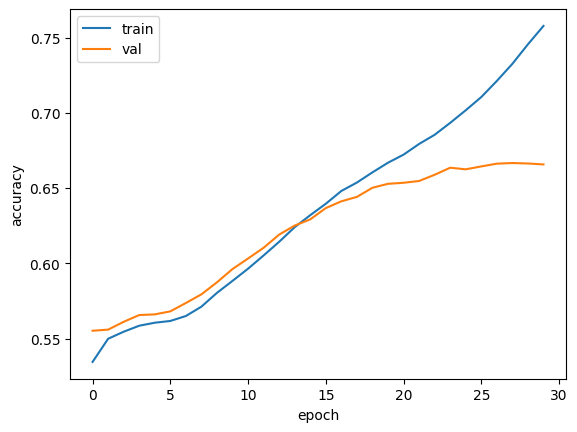

In [14]:
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend()
plt.show()

In [15]:
# translate some product-ish sentences + a few from the test set
def translate(sentence):
    seq = tok_eng.texts_to_sequences([sentence])
    seq = pad_sequences(seq, maxlen=eng_len, padding="post")
    pred = np.argmax(model.predict(seq, verbose=0), axis=-1)
    return tok_frn.sequences_to_texts(pred)[0]

for s in ["I like this shirt.", "This is very good.", "It is too expensive.", "Thank you."]:
    print(f"{s:25} -> {translate(s)}")

print()
for i in range(5):
    eng = tok_eng.sequences_to_texts([X_test[i]])[0]
    real = tok_frn.sequences_to_texts([y_test[i]])[0]
    print(f"EN:   {eng}")
    print(f"REAL: {real}")
    print(f"PRED: {translate(eng)}")
    print()

I like this shirt.        -> j'aime tout plage
This is very good.        -> c'est vraiment très
It is too expensive.      -> c'est trop dangereux
Thank you.                -> maîtrisez toi

EN:   i feel it now
REAL: je le sens maintenant
PRED: je me sens

EN:   he took off his clothes
REAL: il ôta ses vêtements
PRED: il a éteint ses

EN:   don't miss this amazing opportunity
REAL: ne manque pas cette incroyable occasion
PRED: ne pas pas cette cette petite

EN:   everything's wrong
REAL: rien ne va
PRED: tout va mal

EN:   my client wants to plead guilty
REAL: mon client souhaite plaider coupable
PRED: la moins plus à



> **Notes:**
>
> The model gets the short, common sentences mostly right, but it messes up longer or rare ones since the whole sentence gets squeezed into a single vector and there's no attention. For the e-commerce use case it's an ok starting point, but for real product listings you'd want an attention / transformer model (or just a pretrained one like MarianMT `Helsinki-NLP/opus-mt-en-fr`) trained on way more data.